# Defining a Bayesian model with modelgami

A modelgami model is a handful of ordinary JAX functions on **dicts of arrays**:

- a paragami pattern for the parameters,
- `log_prior(params, hyper)`,
- a log likelihood, either for one observation (`log_lik_one(params, datum, hyper)`, for exchangeable data) or for the whole data set (`log_lik(params, data, hyper)`),
- optionally, samplers for the prior and the data, and extra validation checks.

There is no modelling language. Everything else (log densities in folded, flat or free form, pointwise and weighted likelihoods, minibatches, simulation, ArviZ export) is generated from these.

The example is a robust regression: $y_n \sim \text{Student-}t_\nu(x_n^\top \beta, \sigma)$, with priors $\beta \sim N(0, s^2 I)$, $\sigma \sim \text{Exponential}(1)$ and $\nu \sim \text{Gamma}(2, 0.1)$.

Run `./setup_venv.sh` in this folder once and register the kernel it prints; this notebook uses that kernel ("Python (modelgami)").

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
from jax.scipy import stats

import paragami as pg
import modelgami as mg

jax.config.update("jax_enable_x64", True)

## Simulated data

Exchangeable data are a dict of arrays that share a leading observation axis (or, equivalently, a list of per-observation dicts).

In [2]:
n, p = 200, 3
k1, k2 = jax.random.split(jax.random.PRNGKey(0))
X = jnp.concatenate([jnp.ones((n, 1)), jax.random.normal(k1, (n, p - 1))], axis=1)
beta_true = jnp.array([1.0, -2.0, 0.5])
y = X @ beta_true + 0.7 * jax.random.t(k2, 4.0, (n,))
data = {"x": X, "y": y}

## The model: plain functions

In [3]:
params_pattern = pg.PatternDict(
    beta=pg.NumericVectorPattern(p),
    sigma=pg.NumericScalarPattern(lb=0.0),
    nu=pg.NumericScalarPattern(lb=0.0),
)
hyper = {"beta_scale": 5.0}

def log_prior(params, hyper):
    return (stats.norm.logpdf(params["beta"], 0.0, hyper["beta_scale"]).sum()
            + stats.expon.logpdf(params["sigma"])
            + stats.gamma.logpdf(params["nu"], 2.0, scale=10.0))

def log_lik_one(params, datum, hyper):
    # One observation: datum = {"x": (p,), "y": ()}
    z = (datum["y"] - datum["x"] @ params["beta"]) / params["sigma"]
    return stats.t.logpdf(z, params["nu"]) - jnp.log(params["sigma"])

def sample_prior(key, hyper):
    kb, ks, kn = jax.random.split(key, 3)
    return {
        "beta": hyper["beta_scale"] * jax.random.normal(kb, (p,)),
        "sigma": jax.random.exponential(ks),
        "nu": 10.0 * jax.random.gamma(kn, 2.0),
    }

def sample_one(key, params, datum, hyper):
    # A new y for one observation, keeping its covariates.
    y = datum["x"] @ params["beta"] + params["sigma"] * jax.random.t(key, params["nu"])
    return dict(datum, y=y)

def check_data(data):
    # Optional extra validation, run when the model is built.
    if not jnp.all(jnp.isfinite(data["y"])):
        return "y has non-finite values"

model = mg.Model(
    name="robust_regression",
    params_pattern=params_pattern,
    data=data,
    hyper=hyper,
    log_prior=log_prior,
    log_lik_one=log_lik_one,
    sample_prior=sample_prior,
    sample_one=sample_one,
    check_data=check_data,
)
model.capabilities

{'name': 'robust_regression',
 'free_dim': 5,
 'exchangeable': True,
 'n_obs': 200,
 'has_prior': True,
 'can_sample_prior': True,
 'can_sample_data': True,
 'pattern_types': ['NumericScalarPattern(bounded)', 'NumericVectorPattern']}

## The same model as a class

If you prefer, the same hooks can be methods of a subclass. The two forms are interchangeable. Here the subclass reuses the functions above.

In [4]:
class RobustRegression(mg.Model):
    def params_pattern(self):
        return params_pattern

    def log_prior(self, params, hyper):
        return log_prior(params, hyper)

    def log_lik_one(self, params, datum, hyper):
        return log_lik_one(params, datum, hyper)

model_cls = RobustRegression(data=data, hyper=hyper)
params = model.random_params(jax.random.PRNGKey(1))
print(model.log_lik(params), model_cls.log_lik(params))

-618.904782579757 -618.904782579757


## Log densities in each representation

`log_density_fn(which, params_as=...)` returns a JAX function of the parameters in folded (dict), flat or free (unconstrained vector) form. By default each function is, up to a constant, the density it names with respect to the parameters you pass. So in free form the log Jacobian is included for `"joint"` and `"prior"` and not for `"lik"`. `jacobian=True/False` overrides the default.

In [5]:
joint_folded = model.log_density_fn("joint", params_as="folded")
joint_free = model.log_density_fn("joint", params_as="free")
joint_free_nojac = model.log_density_fn("joint", params_as="free", jacobian=False)

x = model.flatten_params(params, to_free=True)
print("free dimension:", model.free_dim)
print("folded:", joint_folded(params))
print("free, with Jacobian:", joint_free(x))
print("free, without Jacobian:", joint_free_nojac(x))
print("difference = log Jacobian:", joint_free(x) - joint_free_nojac(x),
      model.params_pattern.free_to_folded_log_abs_det(x))

free dimension: 5


folded: -634.6051025959725
free, with Jacobian: -634.4807495619929
free, without Jacobian: -634.6051025959725
difference = log Jacobian: 0.12435303397967346 0.12435303397962127


In [6]:
grad = jax.jit(jax.grad(joint_free))
hess = jax.jit(jax.hessian(joint_free))
print("gradient:", grad(x))
print("Hessian-vector product:", mg.hvp(joint_free)(x, jnp.ones_like(x)))
print("Hessian diagonal:", jnp.diag(hess(x)))

gradient: [ 45.89937019 -24.66707056   5.52571989 -41.14248556  95.25834276]


Hessian-vector product: [ -62.87153872  -27.75962125  -20.59926314 -110.40617462  -45.82038807]


Hessian diagonal: [-12.30361134 -14.45690124 -16.56672389 -92.92268279 -46.90539639]


## Exchangeable data: pointwise, weighted and subset likelihoods

Because the likelihood was given for one observation, modelgami can evaluate it pointwise, with data weights, or on a minibatch.

In [7]:
pw = model.log_lik_pointwise(params)
print("pointwise shape:", pw.shape, "  sum matches log_lik:", jnp.allclose(pw.sum(), model.log_lik(params)))

# Weighted likelihood; the gradient in the weights is each observation's influence.
w = jnp.ones(model.n_obs)
influence = jax.grad(lambda w: model.log_lik(params, weights=w))(w)
print("d log_lik / d w equals the pointwise values:", jnp.allclose(influence, pw))

# A minibatch, scaled by N / batch size to be unbiased for the full likelihood.
idx = jnp.arange(20)
print("subset estimate:", model.log_lik_subset(params, idx), "  full:", model.log_lik(params))

# Bootstrap weights.
print("bootstrap log_lik:", model.log_lik(params, weights=model.bootstrap_weights(jax.random.PRNGKey(2))))

pointwise shape: (200,)   sum matches log_lik: True


d log_lik / d w equals the pointwise values: True


subset estimate: -628.4991954275696   full: -618.904782579757


bootstrap log_lik: -619.5352721045864


## Simulation

`sample_prior` draws parameters, and `sample_data` draws a full data set from `sample_one`. Together they give a prior predictive check.

In [8]:
keys = jax.random.split(jax.random.PRNGKey(3), 500)
prior_draws = jax.vmap(model.sample_prior)(keys)
print({k: v.shape for k, v in prior_draws.items()})

sim = model.sample_data(jax.random.PRNGKey(4), params)
print("simulated data keys:", list(sim), " y shape:", sim["y"].shape)

{'beta': (500, 3), 'nu': (500,), 'sigma': (500,)}


simulated data keys: ['x', 'y']  y shape: (200,)


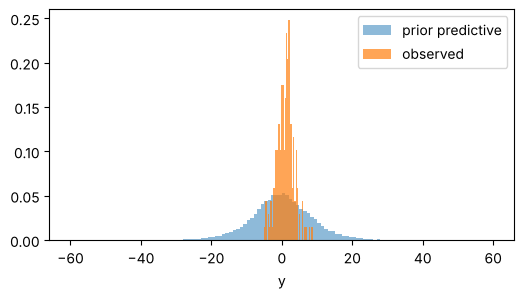

In [9]:
import matplotlib.pyplot as plt

y_rep = jax.vmap(lambda k, prm: model.sample_data(k, prm)["y"])(
    jax.random.split(jax.random.PRNGKey(5), 200), jax.tree_util.tree_map(lambda a: a[:200], prior_draws))
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(np.clip(np.asarray(y_rep).ravel(), -60, 60), bins=120, density=True, alpha=0.5, label="prior predictive")
ax.hist(np.asarray(y), bins=40, density=True, alpha=0.7, label="observed")
ax.set_xlabel("y"); ax.legend(); plt.show()

## Validation, new data, and checking the model

`validate_params` and `validate_data` combine the pattern checks with your own. `with_data` gives the same model with new data. `check_model_contract` checks that all of the generated pieces agree with each other.

In [10]:
for check in [lambda: model.validate_params(dict(params, sigma=-1.0)),
              lambda: model.with_data(dict(data, y=data["y"].at[0].set(jnp.nan)))]:
    try:
        check()
    except mg.ValidationError as e:
        print("ValidationError:", str(e)[-80:])

small = model.with_data({"x": X[:50], "y": y[:50]})
print("n_obs:", small.n_obs)

ValidationError: 0.0, 'ub': inf, 'order': 'C'})}): ['sigma'] values must be > lb = 0.0 (min -1.0)
ValidationError: ', {'shape': (200,), 'lb': -inf, 'ub': inf, 'order': 'C'})}): ['y'] contains NaN


n_obs: 50


In [11]:
from modelgami.testing import check_model_contract
check_model_contract(model)

True

## Optional: distributions instead of separate density and sampler

If you'd rather write the likelihood once and get both its density and its sampler, return the observation's distribution (NumPyro or TFP distributions). This is optional; the separate functions above always work. A NumPyro program can also be turned into a model with `mg.from_numpyro`.

In [12]:
import numpyro.distributions as dist

def obs_dists_one(params, datum, hyper):
    return {"y": dist.StudentT(params["nu"], datum["x"] @ params["beta"], params["sigma"])}

model_dists = mg.Model(params_pattern=params_pattern, data=data, hyper=hyper,
                       log_prior=log_prior, obs_dists_one=obs_dists_one)
print(model_dists.log_lik(params), model.log_lik(params))

-618.904782579757 -618.904782579757
